In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
data = pd.read_csv("dataset.csv")

In [3]:
data

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [4]:
print("Original dataset shape:", data.shape)

print("\nPopularity distribution:")
print(data['popularity'].describe())

print("\nPopularity value counts:")
print(data['popularity'].value_counts().sort_index())

Original dataset shape: (114000, 21)

Popularity distribution:
count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64

Popularity value counts:
popularity
0      16020
1       2140
2       1036
3        585
4        389
       ...  
96         7
97         8
98         7
99         1
100        2
Name: count, Length: 101, dtype: int64


In [5]:
data['popularity_category'] = pd.cut(data['popularity'],bins=[-1, 39, 69, 100],labels=['Low', 'Medium', 'High'])
category_counts = data['popularity_category'].value_counts()
print(category_counts)

popularity_category
Low       65413
Medium    43115
High       5472
Name: count, dtype: int64


In [6]:
print("\nPercentage Distribution:")
print(data['popularity_category'].value_counts(normalize=True) * 100)


Percentage Distribution:
popularity_category
Low       57.379825
Medium    37.820175
High       4.800000
Name: proportion, dtype: float64


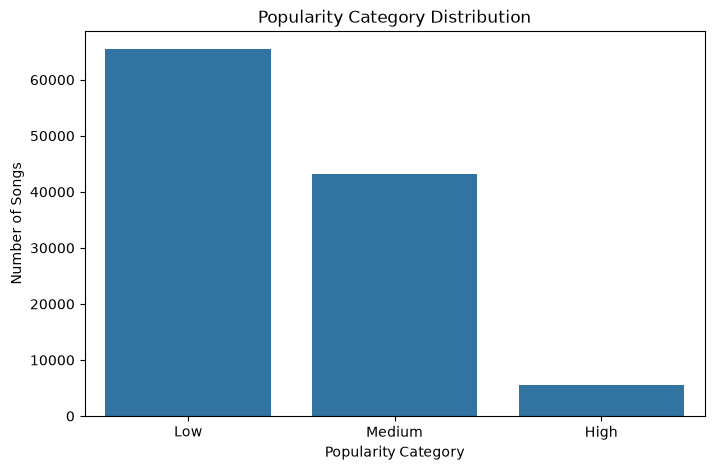

In [7]:
plt.figure(figsize=(8,5))
sns.countplot(data=data,x='popularity_category')
plt.title('Popularity Category Distribution')
plt.xlabel('Popularity Category')
plt.ylabel('Number of Songs')
plt.show()

In [8]:
print(data['popularity_category'].value_counts())

popularity_category
Low       65413
Medium    43115
High       5472
Name: count, dtype: int64


#### DATA SAMPLING (TO TAKE RECORD THAT IS ONLY NEEDED FOR THE PREDICTION.SO IT CAN AVOID CLASS IMBALANCE)

In [9]:
low = data[data['popularity_category'] == 'Low'].sample(n=2167, random_state=42)
med = data[data['popularity_category'] == 'Medium'].sample(n=2167, random_state=42)
high = data[data['popularity_category'] == 'High'].sample(n=2166, random_state=42)

In [10]:
sampled_data = pd.concat([low, med, high])

In [11]:
sampled_data

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,popularity_category
99763,99763,2qI0dxrLFzm5oCgjiYc265,Prateek Kuhad,cold/mess,for your time,35,186873,False,0.578,0.723,...,1,0.0360,0.012900,0.000137,0.3340,0.631,130.997,4,singer-songwriter,Low
110877,110877,120Tni2Xm0XoIvGt0o8NYD,NG Rezonance,"Syncopy Radio Edits, Vol. 2",Enigma - Radio Edit,29,134285,False,0.439,0.972,...,0,0.0618,0.000141,0.913000,0.0986,0.182,146.980,4,trance,Low
104443,104443,0ILCRsebj1Z3K4xM8VfxPw,Natalia Jiménez,Natalia Jiménez,Reflejo,30,251200,False,0.557,0.520,...,1,0.0248,0.321000,0.000015,0.2320,0.325,161.190,4,spanish,Low
17992,17992,0l0515yhITEQ0Lwa8Fc5mS,Donbor,Restore,Born Killer,15,197454,False,0.634,0.622,...,1,0.0456,0.006280,0.000661,0.0784,0.430,109.960,4,club,Low
103645,103645,2i6Zgt3uFaupWIcpvRORMn,B.B. King,Home For Christmas 2022,Please Come Home For Christmas,0,291440,False,0.498,0.533,...,1,0.0245,0.261000,0.047100,0.3140,0.288,96.459,3,soul,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
81055,81055,3sqRODOZ1Z6hR4F2tnFAlg,Maninder Buttar,Sakhiyaan,Sakhiyaan,73,179325,False,0.706,0.674,...,1,0.0440,0.300000,0.000000,0.2020,0.359,83.001,4,pop,High
68968,68968,4r9jkMEnArtWGH2rL2FZl0,Bad Bunny,YHLQMDLG,A Tu Merced,83,175918,False,0.860,0.791,...,1,0.0568,0.169000,0.000106,0.1060,0.887,92.023,4,latino,High
3464,3464,3ZOEytgrvLwQaqXreDs2Jx,Red Hot Chili Peppers,By the Way (Deluxe Edition),Can't Stop,82,269000,False,0.618,0.938,...,1,0.0456,0.017900,0.000000,0.1670,0.875,91.455,4,alternative,High
53008,53008,3g0mEQx3NTanacLseoP0Gw,The Chainsmokers;ILLENIUM;Lennon Stella,World War Joy,Takeaway,75,209880,False,0.528,0.511,...,1,0.0324,0.126000,0.000000,0.1010,0.351,100.100,4,house,High


In [12]:
#shuffling the data that is sanmpled.
sampled_data = sampled_data.sample(frac=1, random_state=42).reset_index(drop=True)

In [13]:
sampled_data

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,popularity_category
0,89975,7F7kL3i6SDEIbDcoJZGiig,Daddy Yankee,Sígueme Y Te Sigo,Sígueme Y Te Sigo,66,209786,False,0.736,0.878,...,0,0.0428,0.069000,0.000064,0.756,0.6630,100.025,4,reggaeton,Medium
1,53625,0MWiSBKm8Avs8iDIxcertp,Anne-Marie;Little Mix,Therapy,Kiss My (Uh Oh),71,176800,False,0.638,0.878,...,0,0.0484,0.015100,0.000223,0.308,0.4810,103.948,4,house,High
2,22749,1qwuOsnKOhrEbOLKZjVVSR,Benediction;Kam Lee,Scriptures,Progenitors of a New Paradigm,21,324731,False,0.453,0.996,...,1,0.1160,0.000059,0.648000,0.156,0.1260,150.002,4,death-metal,Low
3,14363,44ZCbIUyIvHkq3zdx6zoiG,CoComelon,"CoComelon Kids Hits, Vol. 5",Breakfast Song,51,142509,False,0.827,0.327,...,1,0.0399,0.605000,0.000000,0.110,0.9700,150.034,4,children,Medium
4,2507,1xLs8Mu1QEVbGCpyHQ2r2U,Dominic Fike,What Could Possibly Go Wrong,Why,71,139906,True,0.684,0.856,...,1,0.0411,0.342000,0.007280,0.109,0.3430,117.027,4,alt-rock,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6495,9579,0zGnDcTwcR85dMKmhftA0C,Jefferson & Suellen,Segura Na Minha Mão,Segura Na Minha Mão,44,391895,False,0.384,0.502,...,1,0.0321,0.486000,0.000000,0.511,0.1470,130.042,4,brazil,Medium
6496,34002,1rDjwexewf4hrdZT7SRNsH,Faridkot;Amar Jalal,Nasha (Equals Sessions) - Single,Nasha (Equals Sessions),70,287573,False,0.780,0.460,...,1,0.0851,0.455000,0.000141,0.061,0.7880,124.007,4,folk,High
6497,53219,3fGW43fnu3OHEw6ohTC2Bw,Anne-Marie;Niall Horan,Therapy,Our Song,71,163733,False,0.572,0.759,...,1,0.0506,0.127000,0.000000,0.224,0.5190,80.950,4,house,High
6498,91451,2AT8iROs4FQueDv2c8q2KE,Arctic Monkeys,AM,R U Mine?,83,201726,False,0.288,0.758,...,0,0.0371,0.006160,0.000000,0.303,0.6190,97.094,4,rock,High


In [14]:
print("New dataset shape:", sampled_data.shape)  # we have done the sampling because of too large dataset. so we just have class balamnced data.
#that having 6500 record and 22 features.
print("\nCategory distribution:")
print(sampled_data['popularity_category'].value_counts())

New dataset shape: (6500, 22)

Category distribution:
popularity_category
Low       2167
Medium    2167
High      2166
Name: count, dtype: int64


In [15]:
print("Number of duplicate rows:", sampled_data.duplicated().sum())

Number of duplicate rows: 0


In [16]:
print("Duplicate track IDs:", sampled_data['track_id'].duplicated().sum())

Duplicate track IDs: 515


In [17]:
#taking only unique track id's
duplicate_tracks = sampled_data[sampled_data['track_id'].duplicated(keep=False)]
duplicate_tracks.head(10)

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,popularity_category
4,2507,1xLs8Mu1QEVbGCpyHQ2r2U,Dominic Fike,What Could Possibly Go Wrong,Why,71,139906,True,0.684,0.856,...,1,0.0411,0.34200,0.007280,0.1090,0.343,117.027,4,alt-rock,High
12,57107,6kxaaIeowajN7w21PfMLbu,Halsey,So Good,So Good,77,176058,False,0.576,0.627,...,0,0.0449,0.03850,0.000000,0.1810,0.311,164.998,4,indie,High
47,30680,3zU9rdflI65tK4dkkNSp77,Alesso;Tove Lo,Forever,Heroes (we could be),72,210013,False,0.503,0.748,...,1,0.0619,0.03050,0.000000,0.3430,0.356,125.896,4,edm,High
49,71004,7o2CTH4ctstm8TNelqjb51,Guns N' Roses,Appetite For Destruction,Sweet Child O' Mine,84,354520,True,0.454,0.910,...,1,0.0448,0.08660,0.099600,0.1160,0.629,125.116,4,metal,High
58,3263,4Yf5bqU3NK4kNOypcrLYwU,Linkin Park,Meteora,Faint,77,162600,False,0.554,0.978,...,1,0.1310,0.11100,0.000000,0.0731,0.594,135.095,4,alternative,High
59,30216,7Feaw9WAEREY0DUOSXJLOM,Martin Garrix;Macklemore;Fall Out Boy,Summer Days (feat. Macklemore & Patrick Stump ...,Summer Days (feat. Macklemore & Patrick Stump ...,74,163804,True,0.661,0.723,...,0,0.0566,0.17900,0.000012,0.1400,0.316,113.778,4,edm,High
64,71421,5cZqsjVs6MevCnAkasbEOX,Limp Bizkit,Significant Other,Break Stuff,77,166706,True,0.432,0.884,...,1,0.1300,0.01270,0.000527,0.1660,0.624,108.948,4,metal,High
73,30555,2CPqh63wRVscbceKcPxwvv,Mike Perry;shy martin,The Ocean (feat. Shy Martin),The Ocean (feat. Shy Martin),72,183414,False,0.632,0.575,...,1,0.0290,0.02250,0.000002,0.1040,0.188,90.037,4,edm,High
80,2101,0VF7YLIxSQKyNiFL3X6MmN,The Neighbourhood,Chip Chrome & The Mono-Tones (Deluxe),Stargazing,76,217026,False,0.512,0.483,...,1,0.0298,0.00304,0.001100,0.1200,0.367,160.009,4,alt-rock,High
91,37057,2hrUO4drrO63i7FYbCLBl2,Clean Bandit;Sean Paul;Anne-Marie,What Is Love? (Deluxe Edition),Rockabye (feat. Sean Paul & Anne-Marie),72,251173,False,0.717,0.730,...,0,0.0568,0.38300,0.000000,0.3980,0.792,102.002,4,funk,High


In [18]:
duplicate_tracks.groupby('track_id')['track_genre'].nunique().sort_values(ascending=False).head(10)

track_id
6TfBA04WJ3X1d1wXhaCFVT    5
2kkvB3RNRzwjFdGhaUA0tz    5
6HSXNV0b4M4cLJ7ljgVVeh    4
6i1g5ZRmJZAkDwBaUZ3f2i    4
4MzXwWMhyBbmu6hOcLVD49    4
31AOj9sFz2gM0O3hMARRBx    4
7nnWIPM5hwE3DaUBkvOIpy    4
1Eolhana7nKHYpcYpdVcT5    4
116H0KvKr2Zl4RPuVBruDO    4
7oVEtyuv9NBmnytsCIsY5I    3
Name: track_genre, dtype: int64

In [20]:
duplicate_tracks[['track_id', 'track_name', 'artists', 'track_genre', 'popularity']].head(20)

,track_id,track_name,artists,track_genre,popularity
4,1xLs8Mu1QEVbGCpyHQ2r2U,Why,Dominic Fike,alt-rock,71
12,6kxaaIeowajN7w21PfMLbu,So Good,Halsey,indie,77
47,3zU9rdflI65tK4dkkNSp77,Heroes (we could be),Alesso;Tove Lo,edm,72
49,7o2CTH4ctstm8TNelqjb51,Sweet Child O' Mine,Guns N' Roses,metal,84
58,4Yf5bqU3NK4kNOypcrLYwU,Faint,Linkin Park,alternative,77
59,7Feaw9WAEREY0DUOSXJLOM,Summer Days (feat. Macklemore & Patrick Stump ...,Martin Garrix;Macklemore;Fall Out Boy,edm,74
64,5cZqsjVs6MevCnAkasbEOX,Break Stuff,Limp Bizkit,metal,77
73,2CPqh63wRVscbceKcPxwvv,The Ocean (feat. Shy Martin),Mike Perry;shy martin,edm,72
80,0VF7YLIxSQKyNiFL3X6MmN,Stargazing,The Neighbourhood,alt-rock,76
91,2hrUO4drrO63i7FYbCLBl2,Rockabye (feat. Sean Paul & Anne-Marie),Clean Bandit;Sean Paul;Anne-Marie,funk,72


In [21]:
duplicate_groups = duplicate_tracks.groupby('track_id')
print("Number of duplicate track groups:", duplicate_groups.ngroups)

Number of duplicate track groups: 427


In [22]:
duplicate_counts = duplicate_tracks.groupby('track_id').size()
print(duplicate_counts.value_counts().sort_index())

2    350
3     68
4      7
5      2
Name: count, dtype: int64


In [23]:
# track IDs appearing five times or more.
multiple_tracks = duplicate_counts[duplicate_counts >= 3]
print("Track IDs appearing 3 or more times:")
print(multiple_tracks.sort_values(ascending=False))

Track IDs appearing 3 or more times:
track_id
2kkvB3RNRzwjFdGhaUA0tz    5
6TfBA04WJ3X1d1wXhaCFVT    5
4MzXwWMhyBbmu6hOcLVD49    4
116H0KvKr2Zl4RPuVBruDO    4
1Eolhana7nKHYpcYpdVcT5    4
                         ..
75FEaRjZTKLhTrFGsfMUXR    3
7o2CTH4ctstm8TNelqjb51    3
7oVEtyuv9NBmnytsCIsY5I    3
7xnElMPFCmSlMJ0AY2hnxc    3
7y3c1oJMY1CwwtOZ84Qovu    3
Length: 77, dtype: int64


In [24]:
#whether these repeated track IDs have different genres, popularity values or artist names.
multiple_track_details = duplicate_tracks[duplicate_tracks['track_id'].isin(multiple_tracks.index)]
multiple_track_details[['track_id', 'track_name', 'artists', 'track_genre', 'popularity']].head(20)

,track_id,track_name,artists,track_genre,popularity
49,7o2CTH4ctstm8TNelqjb51,Sweet Child O' Mine,Guns N' Roses,metal,84
58,4Yf5bqU3NK4kNOypcrLYwU,Faint,Linkin Park,alternative,77
91,2hrUO4drrO63i7FYbCLBl2,Rockabye (feat. Sean Paul & Anne-Marie),Clean Bandit;Sean Paul;Anne-Marie,funk,72
157,6G8xvLFNkXy3HM5EbQI6c8,sail away,lovelytheband,alt-rock,71
200,0gmbgwZ8iqyMPmXefof8Yf,How You Remind Me,Nickelback,grunge,80
202,0ADZ5dmXhlfzjMw6lefoPl,Far Away,Nickelback,alternative,73
203,21Qsj3cMVCx2xF2EVVNbEu,Fell In Love With a Girl,The White Stripes,punk,72
237,5cpJFiNwYyWwFLH0V6B3N8,Del Mar,Ozuna;Doja Cat;Sia,reggae,75
254,5UWwZ5lm5PKu6eKsHAGxOk,Everlong,Foo Fighters,alt-rock,84
270,2W779g2UrRZtVdf3FcEOO1,In My Mind,Lyn Lapid,songwriter,73


In [25]:
#Compare the audio features
duplicate_feature_check = duplicate_tracks.groupby('track_id').agg(
    total_records=('track_id', 'size'),
    different_genres=('track_genre', 'nunique'),
    different_popularity=('popularity', 'nunique'),
    different_danceability=('danceability', 'nunique'),
    different_energy=('energy', 'nunique'),
    different_tempo=('tempo', 'nunique')
)
duplicate_feature_check.head(10)

,total_records,different_genres,different_popularity,different_danceability,different_energy,different_tempo
track_id,,,,,,
01Q3OyB05mLgH01fpdAMPP,2,2,1,1,1,1
01Rc6yXYtujAnMaR1NME11,2,2,1,1,1,1
01TyFEZu6mHbffsVfxgrFn,2,2,1,1,1,1
02sas1xqIwRm7iWSoHDvKe,2,2,1,1,1,1
05NYcsjJwOYq4jIiKPVj9p,2,2,1,1,1,1
05SBRd4fXgn8FX7bf8BCAE,2,2,1,1,1,1
05bfbizlM5AX6Mf1RRyMho,2,2,1,1,1,1
06vNG6CiV4k8oNA0wUUAO7,2,2,1,1,1,1
07nH4ifBxUB4lZcsf44Brn,2,2,1,1,1,1


In [26]:
#Check all audio features
audio_features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]
duplicate_feature_check = duplicate_tracks.groupby('track_id')[audio_features].nunique()
duplicate_feature_check.head(10)

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
track_id,,,,,,,,,
01Q3OyB05mLgH01fpdAMPP,1,1,1,1,1,1,1,1,1
01Rc6yXYtujAnMaR1NME11,1,1,1,1,1,1,1,1,1
01TyFEZu6mHbffsVfxgrFn,1,1,1,1,1,1,1,1,1
02sas1xqIwRm7iWSoHDvKe,1,1,1,1,1,1,1,1,1
05NYcsjJwOYq4jIiKPVj9p,1,1,1,1,1,1,1,1,1
05SBRd4fXgn8FX7bf8BCAE,1,1,1,1,1,1,1,1,1
05bfbizlM5AX6Mf1RRyMho,1,1,1,1,1,1,1,1,1
06vNG6CiV4k8oNA0wUUAO7,1,1,1,1,1,1,1,1,1
07nH4ifBxUB4lZcsf44Brn,1,1,1,1,1,1,1,1,1


In [28]:
all_features_identical = (duplicate_feature_check == 1).all(axis=1)
print("Tracks with identical audio features:",all_features_identical.sum())
print("Tracks with different audio features:",(~all_features_identical).sum())

Tracks with identical audio features: 427
Tracks with different audio features: 0


In [29]:
#Create a genre mapping
genre_mapping = (sampled_data.groupby('track_id')['track_genre'].apply(lambda x: ', '.join(sorted(set(x)))).reset_index())
genre_mapping.head(10)

,track_id,track_genre
0,00KfIFi2TpAaQGPbRbFbKJ,metal
1,00PBSElFPJbnIcFS7orAm2,reggaeton
2,00QBHaaP4KUcjlmxWriMbC,spanish
3,00RrOc0e6AlGWXRd9FERYR,tango
4,00ZyHdRmAxhS8iswmEqCTn,hardstyle
5,00frrtnFga2Bz2s06EazHw,hardstyle
6,00gFptV5vcCXHgcXtFr3cT,electro
7,014SIjoLDG1Ku19c5FlDYh,rock
8,015BCBzbTyaGy01VopJlR9,groove
9,016iTFDW3ZCIxnw6NN2JZP,drum-and-bass
